# Issue #9: Data Preprocessing – EV Charging Sessions

**Input:** `acn_structured_sessions.csv` (Issue #3)  
**Outputs (repository root):** `acn_clean_sessions.csv`, `acn_flagged_sessions.csv`, `preprocessing_summary.csv`, `preprocessing_report.md`

**Rules for this notebook**
- Every removal is a named rule with its threshold defined in one place; every removed row is saved with its reason.
- Thresholds are set *after* the distributions are inspected (Section 4).
- Rules are labelled **ACTIVE** (removed rows), **guard** (sanity check expected to affect nothing) or **fix** (value corrected, row kept).
- All statements about the data in the report (Section 10) are generated from the data, so they stay correct when the input changes.

In [1]:
import ast
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 60)

from pathlib import Path
def find_root(marker):
    """Repository root = the folder holding `marker` (this folder or its parent)."""
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found in this folder or its parent")

ROOT = find_root("acn_structured_sessions.csv")
IN_FILE = ROOT / "acn_structured_sessions.csv"
df = pd.read_csv(IN_FILE)
raw_rows = len(df)
print("Loaded shape:", df.shape)
df.head(3)

Loaded shape: (31424, 13)


,_id,sessionID,userID,stationID,spaceID,siteID,clusterID,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,timezone,userInputs
0,5bc90cb9f9af8b0d7fe77cd2,2_39_78_362_2018-04-25 11:08:04.400812,NaN,2-39-78-362,CA-496,2,39,"Wed, 25 Apr 2018 11:08:04 GMT","Wed, 25 Apr 2018 13:20:10 GMT","Wed, 25 Apr 2018 13:21:10 GMT",7.932,America/Los_Angeles,NaN
1,5bc90cb9f9af8b0d7fe77cd3,2_39_95_27_2018-04-25 13:45:09.617470,NaN,2-39-95-27,CA-319,2,39,"Wed, 25 Apr 2018 13:45:10 GMT","Thu, 26 Apr 2018 00:56:16 GMT","Wed, 25 Apr 2018 16:44:15 GMT",10.013,America/Los_Angeles,NaN
2,5bc90cb9f9af8b0d7fe77cd4,2_39_79_380_2018-04-25 13:45:49.962001,NaN,2-39-79-380,CA-489,2,39,"Wed, 25 Apr 2018 13:45:50 GMT","Wed, 25 Apr 2018 23:04:45 GMT","Wed, 25 Apr 2018 14:51:44 GMT",5.257,America/Los_Angeles,NaN


## 1. Missing values

In [2]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
})
missing

,missing,pct_missing,dtype
_id,0,0.00,str
sessionID,0,0.00,str
userID,15036,47.85,float64
stationID,0,0.00,str
spaceID,0,0.00,str
siteID,0,0.00,int64
clusterID,0,0.00,int64
connectionTime,0,0.00,str
disconnectTime,0,0.00,str
doneChargingTime,2055,6.54,str


How each gap is treated is decided in Section 6, not by imputation: a missing `userID` / `userInputs` means the driver did not use the app (an *unclaimed* session, which the operator handled under different rules), so it is kept as a flag; a missing `doneChargingTime` keeps the session and only the derived charging duration and power become unavailable.

In [3]:
# One real (non-null) userInputs value, to check the parser in Section 7 against the actual format
sample = df["userInputs"].dropna().iloc[0] if df["userInputs"].notna().any() else None
print(type(sample))
print(sample)

<class 'str'>
[{'userID': 22, 'milesRequested': 170, 'WhPerMile': 350, 'minutesAvailable': 550, 'modifiedAt': 'Mon, 30 Apr 2018 15:08:54 GMT', 'paymentRequired': True, 'requestedDeparture': 'Tue, 01 May 2018 00:17:49 GMT', 'kWhRequested': 59.5}]


## 2. Duplicate records

In [4]:
dup_report = {
    "duplicate _id": int(df.duplicated("_id").sum()),
    "duplicate sessionID": int(df.duplicated("sessionID").sum()),
    "duplicate stationID + connectionTime": int(df.duplicated(["stationID", "connectionTime"]).sum()),
    "fully identical rows": int(df.duplicated().sum()),
}
dup_report

{'duplicate _id': 0,
 'duplicate sessionID': 0,
 'duplicate stationID + connectionTime': 0,
 'fully identical rows': 0}

## 3. Timestamp validation and time coverage

In [5]:
TS_FORMAT = "%a, %d %b %Y %H:%M:%S GMT"
LOCAL_TZ = "America/Los_Angeles"
ts_cols = ["connectionTime", "disconnectTime", "doneChargingTime"]

for c in ts_cols:
    df[c] = pd.to_datetime(df[c], format=TS_FORMAT, errors="coerce", utc=True)

print("Unparseable / missing after parsing:")
print(df[ts_cols].isna().sum())

print("\nRange (UTC):  ", df["connectionTime"].min(), "->", df["connectionTime"].max())
print("Range (local):", df["connectionTime"].min().tz_convert(LOCAL_TZ), "->",
      df["connectionTime"].max().tz_convert(LOCAL_TZ))

Unparseable / missing after parsing:
connectionTime         0
disconnectTime         0
doneChargingTime    2055
dtype: int64

Range (UTC):   2018-04-25 11:08:04+00:00 -> 2021-09-14 01:52:37+00:00
Range (local): 2018-04-25 04:08:04-07:00 -> 2021-09-13 18:52:37-07:00


In [6]:
checks = {
    "disconnect <= connect": int((df["disconnectTime"] <= df["connectionTime"]).sum()),
    "doneCharging before connect": int((df["doneChargingTime"] < df["connectionTime"]).sum()),
    "doneCharging > disconnect + 5 min": int((df["doneChargingTime"] > df["disconnectTime"] + pd.Timedelta(minutes=5)).sum()),
}
checks

{'disconnect <= connect': 0,
 'doneCharging before connect': 26,
 'doneCharging > disconnect + 5 min': 2}

connectionTime
2018-04     270
2018-05    1776
2018-06    1845
2018-07    2053
2018-08    2430
2018-09    2315
2018-10    2424
2018-11    1309
2018-12     877
2019-01     989
2019-02     934
2019-03     954
2019-04    1035
2019-05     964
2019-06     883
2019-07     820
2019-08     860
2019-09     829
2019-10     930
2019-11     770
2019-12     648
2020-01     822
2020-02     847
2020-03     381
2020-04      24
2020-05      17
2020-06      40
2020-07      66
2020-08       5
2020-11      72
2020-12     201
2021-01     174
2021-02     185
2021-03     254
2021-04     302
2021-05     343
2021-06     442
2021-07     447
2021-08     597
2021-09     290
Freq: M

C:\Users\GNANESH KHANDAVILLI\AppData\Local\Temp\ipykernel_16756\237524342.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  local_month = df["connectionTime"].dt.tz_convert(LOCAL_TZ).dt.to_period("M")




Coverage: 1237 days (~40.7 months)


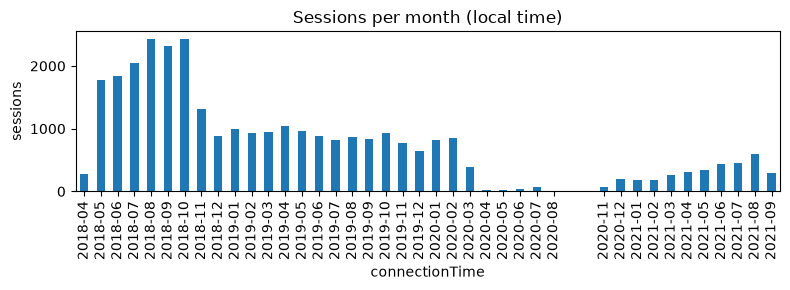

In [7]:
# Coverage: sessions per local month. A hard stop or gaps here limit what the forecasting stage can claim.
local_month = df["connectionTime"].dt.tz_convert(LOCAL_TZ).dt.to_period("M")
monthly = local_month.value_counts().sort_index()
print(monthly.to_string())

span_days = (df["connectionTime"].max() - df["connectionTime"].min()).days
print(f"\nCoverage: {span_days} days (~{span_days/30.4:.1f} months)")

ax = monthly.plot(kind="bar", figsize=(8, 3), title="Sessions per month (local time)")
ax.set_ylabel("sessions"); plt.tight_layout(); plt.show()

In [8]:
# Contiguous coverage: find runs of calendar days separated by gaps longer than MAX_GAP_DAYS.
# The main block (most sessions) is the analysis window. A block outside it is only treated as an
# isolated fragment (removed in Section 6) if it is small; a large second block triggers a warning
# instead, because then the gap is a real problem for forecasting and needs a decision.
MAX_GAP_DAYS = 7          # longest run of empty days tolerated inside the window
FRAGMENT_MAX_SHARE = 0.05 # blocks smaller than this share of sessions are treated as fragments

local_day = df["connectionTime"].dt.tz_convert(LOCAL_TZ).dt.tz_localize(None).dt.normalize()
days = pd.Series(np.sort(local_day.unique()))
block_of_day = (days.diff() > pd.Timedelta(days=MAX_GAP_DAYS + 1)).cumsum()
day_to_block = dict(zip(days, block_of_day))
df["coverage_block"] = local_day.map(day_to_block)

blocks = (df.groupby("coverage_block")
            .agg(start=("connectionTime", "min"), end=("connectionTime", "max"), sessions=("_id", "size")))
blocks["start"] = blocks["start"].dt.tz_convert(LOCAL_TZ).dt.date
blocks["end"] = blocks["end"].dt.tz_convert(LOCAL_TZ).dt.date
blocks["share"] = (blocks["sessions"] / len(df)).round(4)
main_block = int(blocks["sessions"].idxmax())
blocks["role"] = np.where(blocks.index == main_block, "main",
                  np.where(blocks["share"] < FRAGMENT_MAX_SHARE, "fragment -> removed", "LARGE - review"))
print(blocks.to_string())

gap_list = []
for b in range(1, len(blocks)):
    gap_list.append((blocks["end"].iloc[b - 1], blocks["start"].iloc[b],
                     (blocks["start"].iloc[b] - blocks["end"].iloc[b - 1]).days - 1))
for a, b, n in gap_list:
    print(f"Gap: no sessions between {a} and {b} ({n} empty days)")

df["in_coverage"] = (df["coverage_block"] == main_block) | (~blocks.loc[df["coverage_block"], "role"].str.startswith("fragment").values)
large_other = blocks[(blocks.index != main_block) & (blocks["role"] == "LARGE - review")]
if len(large_other):
    print("\nWARNING: a large block lies outside the main window; rows are kept, but the gap must be handled in modelling.")

cov_start, cov_end = blocks.loc[main_block, "start"], blocks.loc[main_block, "end"]
cov_days = (cov_end - cov_start).days + 1
print(f"\nMain contiguous window: {cov_start} -> {cov_end} ({cov_days} days, ~{cov_days/30.4:.1f} months)")
print("Rows outside the window (fragments):", int((~df['in_coverage']).sum()))

                     start         end  sessions   share            role
coverage_block                                                          
0               2018-04-25  2020-08-03     28117  0.8948            main
1               2020-11-18  2021-09-13      3307  0.1052  LARGE - review
Gap: no sessions between 2020-08-03 and 2020-11-18 (106 empty days)


Main contiguous window: 2018-04-25 -> 2020-08-03 (832 days, ~27.4 months)
Rows outside the window (fragments): 0


In [9]:
# Coverage interpretation, generated from the block table above
monthly_counts = monthly.copy()
if gap_list:
    print("Gaps of more than", MAX_GAP_DAYS, "days with no sessions:")
    for a, b, k in gap_list:
        print(f"  {a} -> {b}: {k} empty days")
    print("These days are not zero demand: the source recorded nothing. Blocks that are large are kept, and every "
          "downstream notebook excludes the gap days from daily statistics and models.")
else:
    print("No gap longer than", MAX_GAP_DAYS, "days: the data is one contiguous block.")
low = monthly_counts[monthly_counts < 0.2 * monthly_counts.median()]
if len(low):
    print(f"\nMonths with fewer than 20% of the median monthly volume ({monthly_counts.median():.0f}): "
          + ", ".join(f"{p} ({v})" for p, v in low.items()))
    print("These are real but very low-activity months (e.g. a campus closure); they are kept and handled as a separate regime in the analysis.")

Gaps of more than 7 days with no sessions:
  2020-08-03 -> 2020-11-18: 106 empty days
These days are not zero demand: the source recorded nothing. Blocks that are large are kept, and every downstream notebook excludes the gap days from daily statistics and models.

Months with fewer than 20% of the median monthly volume (795): 2020-04 (24), 2020-05 (17), 2020-06 (40), 2020-07 (66), 2020-08 (5), 2020-11 (72)
These are real but very low-activity months (e.g. a campus closure); they are kept and handled as a separate regime in the analysis.


## 4. Numerical variables (evidence for thresholds)

       kWhDelivered  connected_h
count     31424.000    31424.000
mean          9.253        5.652
std           8.761        5.964
min           0.501        0.034
1%            0.679        0.214
5%            0.877        0.556
50%           6.716        4.730
95%          26.496       11.867
99%          45.035       21.732
max          77.700      245.269


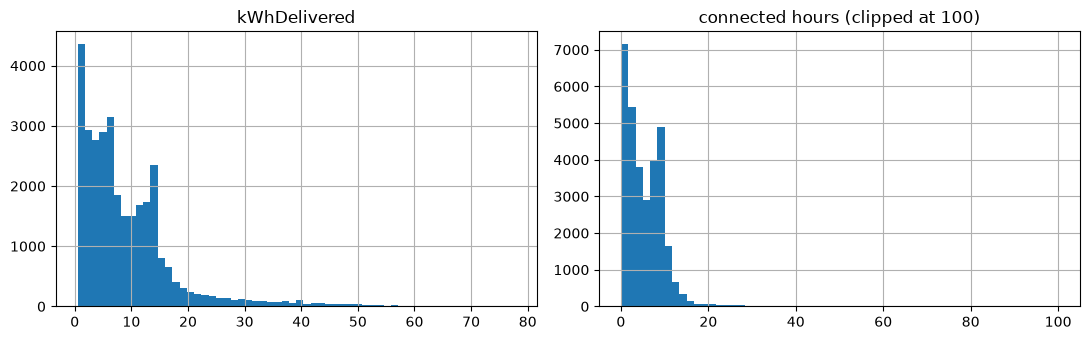

In [10]:
df["kWhDelivered"] = pd.to_numeric(df["kWhDelivered"], errors="coerce")
df["connected_h"] = (df["disconnectTime"] - df["connectionTime"]).dt.total_seconds() / 3600

print(df[["kWhDelivered", "connected_h"]].describe(percentiles=[.01, .05, .5, .95, .99]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["kWhDelivered"].hist(bins=60, ax=ax[0]); ax[0].set_title("kWhDelivered")
df["connected_h"].clip(upper=100).hist(bins=60, ax=ax[1]); ax[1].set_title("connected hours (clipped at 100)")
plt.tight_layout(); plt.show()

In [11]:
print("kWh < 0.1:          ", int((df["kWhDelivered"] < 0.1).sum()))
print("kWh > 100:          ", int((df["kWhDelivered"] > 100).sum()))
print("connected < 1 min:  ", int((df["connected_h"] * 60 < 1).sum()))
print("connected > 72 h:   ", int((df["connected_h"] > 72).sum()))
print("connected > 48 h:   ", int((df["connected_h"] > 48).sum()))
print("connected > 24 h:   ", int((df["connected_h"] > 24).sum()))

kWh < 0.1:           0
kWh > 100:           0
connected < 1 min:   0
connected > 72 h:    37
connected > 48 h:    79
connected > 24 h:    259


In [12]:
# Numbers quoted in the threshold justification (Section 6) and the report
p99_connect_h = float(df["connected_h"].quantile(0.99))
max_connect_h = float(df["connected_h"].max())
share_over_72h = float((df["connected_h"] > 72).mean())
print(f"connected_h: 99th percentile {p99_connect_h:.1f} h, maximum {max_connect_h:.0f} h, share over 72 h {share_over_72h:.2%}")
print(f"kWhDelivered range {df['kWhDelivered'].min():.2f}-{df['kWhDelivered'].max():.1f}; shortest connection {df['connected_h'].min()*60:.1f} min")

connected_h: 99th percentile 21.7 h, maximum 245 h, share over 72 h 0.12%
kWhDelivered range 0.50-77.7; shortest connection 2.1 min


### 4a. Patterns to understand before modelling

1. A sharp spike in `kWhDelivered` around 13–14 kWh.
2. A bimodal connection-time distribution (short stays vs. full-workday stays).

These are findings, not errors — nothing is removed here. Their numbers in the final summary are recomputed on the cleaned data.

In [13]:
spike = df[df["kWhDelivered"].between(13, 14)]
print(f"Sessions in 13-14 kWh: {len(spike)} ({len(spike)/len(df):.1%} of all)")

local_hr = df["connectionTime"].dt.tz_convert(LOCAL_TZ).dt.hour
print("\nSpike sessions - top stations:")
print(spike["stationID"].value_counts().head(5).to_string())
print("\nSpike sessions - arrival hour (local), top 5:")
print(local_hr.loc[spike.index].value_counts().head(5).to_string())
print("\nSpike sessions - share with userID:", round(spike["userID"].notna().mean(), 3),
      "| all sessions:", round(df["userID"].notna().mean(), 3))
print("Spike sessions - median connected hours:", round(spike["connected_h"].median(), 2),
      "| all sessions:", round(df["connected_h"].median(), 2))

Sessions in 13-14 kWh: 2584 (8.2% of all)

Spike sessions - top stations:
stationID
2-39-131-30    127
2-39-139-28    119
2-39-127-19    118
2-39-123-23    108
2-39-125-21    108

Spike sessions - arrival hour (local), top 5:
connectionTime
8     498
9     339
10    209
7     185
17    175

Spike sessions - share with userID: 0.244 | all sessions: 0.522
Spike sessions - median connected hours: 6.62 | all sessions: 4.73


In [14]:
# Is the spike station-specific? Compare each station's spike share with its OWN session count,
# then test whether spike share is the same across stations (chi-square test of homogeneity).
def spike_by_station(frame, min_sessions=50):
    is_spike = frame["kWhDelivered"].between(13, 14)
    t = (frame.assign(spike=is_spike)
              .groupby("stationID")["spike"].agg(sessions="size", spike_sessions="sum"))
    t["spike_share"] = t["spike_sessions"] / t["sessions"]
    t = t[t["sessions"] >= min_sessions]
    table = np.column_stack([t["spike_sessions"], t["sessions"] - t["spike_sessions"]])
    try:
        from scipy.stats import chi2_contingency
        chi2, p, dof, _ = chi2_contingency(table)
    except ImportError:
        chi2, p, dof = np.nan, np.nan, len(t) - 1
    return t.sort_values("spike_share", ascending=False), chi2, p, dof

st, chi2, p_spike, dof = spike_by_station(df)
print(f"Overall spike share: {df['kWhDelivered'].between(13, 14).mean():.1%}")
print(f"Station spike share: min {st['spike_share'].min():.1%}, median {st['spike_share'].median():.1%}, max {st['spike_share'].max():.1%}")
print(f"Chi-square homogeneity test (stations with >= 50 sessions): chi2={chi2:.1f}, dof={dof}, p={p_spike:.3g}")
print("\nHighest spike share:")
print(st.head(5).to_string())

Overall spike share: 8.2%
Station spike share: min 3.5%, median 8.8%, max 21.5%
Chi-square homogeneity test (stations with >= 50 sessions): chi2=415.1, dof=52, p=4.46e-58

Highest spike share:
              sessions  spike_sessions  spike_share
stationID                                          
2-39-138-566       177              38     0.214689
2-39-130-564       138              28     0.202899
2-39-123-557       251              49     0.195219
2-39-129-563        88              16     0.181818
2-39-127-561        90              16     0.177778


In [15]:
# Did spike sessions stop drawing power well before the car left? Idle time = disconnect - doneCharging.
# A large idle share would suggest the charge was limited on the vehicle side (battery full or a set limit)
# rather than by how long the car stayed. Only sessions with a valid doneChargingTime are used.
valid_done = df["doneChargingTime"].between(df["connectionTime"], df["disconnectTime"] + pd.Timedelta(minutes=5))
idle_h = (df["disconnectTime"] - df["doneChargingTime"]).dt.total_seconds() / 3600
is_spike = df["kWhDelivered"].between(13, 14)
for name, m in [("spike", is_spike & valid_done), ("other", ~is_spike & valid_done)]:
    print(f"{name:6s} median idle {idle_h[m].median():.2f} h | share idle > 1 h: {(idle_h[m] > 1).mean():.1%}")

spike  median idle 0.94 h | share idle > 1 h: 49.0%
other  median idle 1.17 h | share idle > 1 h: 52.0%


In [16]:
short = df["connected_h"] < 3
print(f"Short stays (<3 h): {short.mean():.1%}  | median kWh: {df.loc[short,'kWhDelivered'].median():.2f}")
print(f"Long stays (>=3 h): {(~short).mean():.1%} | median kWh: {df.loc[~short,'kWhDelivered'].median():.2f}")

Short stays (<3 h): 36.8%  | median kWh: 4.72
Long stays (>=3 h): 63.2% | median kWh: 8.58


In [17]:
# Is 3 h a sensible split? Locate the density minimum (valley) between the two modes, 1-6 h.
SHORT_STAY_H = 3.0
h = df["connected_h"]
counts, edges = np.histogram(h[(h > 0) & (h < 12)], bins=np.arange(0, 12.25, 0.25))
smooth = pd.Series(counts).rolling(5, center=True, min_periods=1).mean().values
centres = (edges[:-1] + edges[1:]) / 2
window = (centres >= 1) & (centres <= 10)
valley_h = float(centres[window][np.argmin(smooth[window])])
SHORT_STAY_H = round(valley_h * 2) / 2   # split at the valley, nearest 0.5 h
print(f"Density valley between 1 h and 10 h: ~{valley_h:.2f} h -> split used: {SHORT_STAY_H} h")

Density valley between 1 h and 10 h: ~5.88 h -> split used: 6.0 h


> **Station test:** the comparison above uses each station's own session count, so it is not biased toward busy stations the way a top-five count is. A small p-value means spike share genuinely differs between stations; it does not by itself explain the spike. The idle-time comparison is a first check on whether the energy limit comes from the vehicle side.

## 5. Categorical variables

In [18]:
for c in ["siteID", "clusterID", "timezone"]:
    print(c, "->", df[c].nunique(), "unique:", df[c].unique()[:5])
print("stationID unique:", df["stationID"].nunique(), "| spaceID unique:", df["spaceID"].nunique())
df["stationID"].value_counts().describe()

siteID -> 1 unique: [2]
clusterID -> 1 unique: [39]
timezone -> 1 unique: <ArrowStringArray>
['America/Los_Angeles']
Length: 1, dtype: str
stationID unique: 55 | spaceID unique: 55


count      55.000000
mean      571.345455
std       383.557916
min         8.000000
25%       225.500000
50%       565.000000
75%       812.000000
max      1808.000000
Name: count, dtype: float64

## 6. Thresholds and cleaning

**Active rules**
- *Outside contiguous coverage*: rows in a **small** isolated time block (Section 3). Keeping a stray fragment would create a long zero-demand hole. Large blocks separated by a gap are kept; the gap is handled downstream.
- *Connection time over 72 h*: far beyond the 99th percentile printed in Section 4. These sessions are not daily-demand events (vehicle left plugged in or unplug not recorded). **They did occupy a charger**, so they are kept in `acn_flagged_sessions.csv` and added back for occupancy analysis; they are excluded only from per-session energy and duration statistics.

**Guards:** the remaining removal rules are sanity checks expected to affect nothing on this data (see the ranges printed in Section 4). They stay in so the pipeline is safe when more data is added.

**Check (no removal):** overlapping sessions on the same station are counted and flagged, because two cars cannot use one charger at once.

In [19]:
MIN_KWH = 0.1            # guard
MAX_KWH = 100.0          # guard
MIN_CONNECT_MIN = 1.0    # guard
MAX_CONNECT_H = 72.0     # ACTIVE
POWER_MAX_KW = 10.0      # used in Section 8 (value nulled, row kept)

In [20]:
waterfall = [("loaded", "-", len(df), 0)]
flagged = []

def drop(mask, reason, kind):
    """Remove rows where mask is True, save them with the reason, log the count."""
    global df
    n = int(mask.sum())
    if n:
        bad = df[mask].copy()
        bad["drop_reason"] = reason
        flagged.append(bad)
        df = df[~mask].copy()
    waterfall.append((reason, kind, len(df), n))

drop(~df["in_coverage"], "outside contiguous coverage", "ACTIVE")

drop(df.duplicated("_id"), "duplicate _id", "guard")
drop(df.duplicated("sessionID"), "duplicate sessionID", "guard")
drop(df.duplicated(["stationID", "connectionTime"]), "duplicate station+connectionTime", "guard")

drop(df["connectionTime"].isna() | df["disconnectTime"].isna(), "unparseable connect/disconnect time", "guard")
drop(df["disconnectTime"] <= df["connectionTime"], "disconnect not after connect", "guard")

# doneChargingTime: keep the session. Record WHY it is empty before blanking anything.
done_bad = df["doneChargingTime"].notna() & (
    (df["doneChargingTime"] < df["connectionTime"]) |
    (df["doneChargingTime"] > df["disconnectTime"] + pd.Timedelta(minutes=5))
)
df["done_time_inconsistent"] = done_bad                    # source value existed but was impossible
df["done_time_missing"] = df["doneChargingTime"].isna()    # source value never existed
df.loc[done_bad, "doneChargingTime"] = pd.NaT
waterfall.append(("doneChargingTime outside plug-in window -> NaT (rows kept)", "fix", len(df), int(done_bad.sum())))

drop(df["kWhDelivered"].isna(), "kWhDelivered missing/non-numeric", "guard")
drop(df["kWhDelivered"] < MIN_KWH, f"kWhDelivered < {MIN_KWH}", "guard")
drop(df["kWhDelivered"] > MAX_KWH, f"kWhDelivered > {MAX_KWH}", "guard")

df["connected_h"] = (df["disconnectTime"] - df["connectionTime"]).dt.total_seconds() / 3600
drop(df["connected_h"] * 60 < MIN_CONNECT_MIN, f"connected < {MIN_CONNECT_MIN} min", "guard")
drop(df["connected_h"] > MAX_CONNECT_H, f"connected > {MAX_CONNECT_H} h", "ACTIVE")

wf = pd.DataFrame(waterfall, columns=["step", "kind", "rows_remaining", "rows_affected"])
wf

,step,kind,rows_remaining,rows_affected
0,loaded,-,31424,0
1,outside contiguous coverage,ACTIVE,31424,0
2,duplicate _id,guard,31424,0
3,duplicate sessionID,guard,31424,0
4,duplicate station+connectionTime,guard,31424,0
5,unparseable connect/disconnect time,guard,31424,0
6,disconnect not after connect,guard,31424,0
7,doneChargingTime outside plug-in window -> NaT...,fix,31424,28
8,kWhDelivered missing/non-numeric,guard,31424,0
9,kWhDelivered < 0.1,guard,31424,0


In [21]:
# Overlap check: within a station, a session should not start before the previous one ended.
# Counted and flagged only (no removal); a small number usually means clock/record issues.
df = df.sort_values(["stationID", "connectionTime"])
prev_disconnect = df.groupby("stationID")["disconnectTime"].shift()
df["overlaps_prev_session"] = df["connectionTime"] < prev_disconnect
overlap_min = ((prev_disconnect - df["connectionTime"]).dt.total_seconds() / 60).where(df["overlaps_prev_session"])
n_overlap = int(df["overlaps_prev_session"].sum())
print(f"Sessions starting before the previous session on the same station ended: {n_overlap}")
if n_overlap:
    print(f"Overlap length (min): median {overlap_min.median():.1f}, max {overlap_min.max():.1f}")
df = df.sort_values("connectionTime")

Sessions starting before the previous session on the same station ended: 0


In [22]:
print("Rows removed by ACTIVE rules:", int(wf.loc[wf.kind == "ACTIVE", "rows_affected"].sum()))
print("Rows removed by guards (expected 0):", int(wf.loc[wf.kind == "guard", "rows_affected"].sum()))
print("doneChargingTime originally missing (kept):", int(df["done_time_missing"].sum()))
print("doneChargingTime inconsistent -> blanked (kept):", int(df["done_time_inconsistent"].sum()))

Rows removed by ACTIVE rules: 37
Rows removed by guards (expected 0): 0
doneChargingTime originally missing (kept): 2055
doneChargingTime inconsistent -> blanked (kept): 28


## 7. Preprocessing techniques

- Timestamps converted from UTC to local time (`America/Los_Angeles`)
- `userInputs` flattened (latest entry) into `ui_*` columns; number of sessions with more than one entry is recorded; flags added for rows with no user data
- `ui_modifiedAt` and `ui_requestedDeparture` parsed with the same explicit format as the main timestamps; non-null values before and after parsing are compared so a parse failure cannot silently empty a column
- `ui_departure_est` = `ui_modifiedAt + ui_minutesAvailable`, so a departure estimate exists even where `requestedDeparture` is empty
- `userID` kept as an identifier (it became a float in the CSV)
- Columns that carry no information are dropped and listed (nearly-empty `ui_*` columns; `ui_userID` if it duplicates `userID`; constant columns; helper columns)
- Minimal derived fields used for validation: durations, average power, local hour and weekday. Fuller feature engineering belongs to the next stage.

In [23]:
for c in ts_cols:
    df[c + "_local"] = df[c].dt.tz_convert(LOCAL_TZ)

df["charging_h"] = (df["doneChargingTime"] - df["connectionTime"]).dt.total_seconds() / 3600
df["avg_power_kW"] = df["kWhDelivered"] / df["charging_h"].where(df["charging_h"] > 0)
df["hour"] = df["connectionTime_local"].dt.hour
df["dayofweek"] = df["connectionTime_local"].dt.dayofweek
df["date"] = df["connectionTime_local"].dt.date

def load_user_inputs(raw):
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return []
    try:
        val = ast.literal_eval(raw) if isinstance(raw, str) else raw
    except (ValueError, SyntaxError):
        return []
    if isinstance(val, dict):
        return [val]
    return [v for v in val if isinstance(v, dict)] if isinstance(val, list) else []

entries = df["userInputs"].apply(load_user_inputs)
n_multi_entry = int((entries.apply(len) > 1).sum())
print("Sessions with userInputs:", int((entries.apply(len) > 0).sum()),
      "| with more than one entry:", n_multi_entry, "(latest entry used)")

parsed = entries.apply(lambda e: e[-1] if e else {})
flat = pd.DataFrame(parsed.tolist(), index=df.index)
print("userInputs keys found:", list(flat.columns))

df["has_user_input"] = parsed.apply(bool)
df["has_user_id"] = df["userID"].notna()
df["userID"] = df["userID"].astype("Int64").astype("string")

for c in flat.columns:
    df["ui_" + str(c)] = flat[c]

# Parse user timestamps with the explicit format; count non-null before and after so failures are visible.
ui_parse = {}
for c in ["ui_requestedDeparture", "ui_modifiedAt"]:
    if c in df.columns:
        before = int(df[c].notna().sum())
        parsed_ts = pd.to_datetime(df[c], format=TS_FORMAT, errors="coerce", utc=True)
        # fallback for any value in a different format
        retry = parsed_ts.isna() & df[c].notna()
        if retry.any():
            parsed_ts[retry] = pd.to_datetime(df.loc[retry, c], errors="coerce", utc=True, format="mixed")
        after = int(parsed_ts.notna().sum())
        ui_parse[c] = (before, after)
        df[c] = parsed_ts
        print(f"{c}: {before} non-null raw values -> {after} parsed ({before - after} failed)")

if {"ui_modifiedAt", "ui_minutesAvailable"} <= set(df.columns):
    df["ui_departure_est"] = df["ui_modifiedAt"] + pd.to_timedelta(df["ui_minutesAvailable"], unit="min")
    if "ui_requestedDeparture" in df.columns:
        both = df["ui_departure_est"].notna() & df["ui_requestedDeparture"].notna()
        if both.any():
            diff_min = ((df.loc[both, "ui_departure_est"] - df.loc[both, "ui_requestedDeparture"]).dt.total_seconds() / 60).abs()
            print(f"ui_departure_est vs requestedDeparture where both exist (n={int(both.sum())}): median |diff| {diff_min.median():.1f} min")

df = df.drop(columns=["userInputs", "timezone"]).reset_index(drop=True)
df.head(3)

Sessions with userInputs: 16372 | with more than one entry: 2325 (latest entry used)
userInputs keys found: ['userID', 'milesRequested', 'WhPerMile', 'minutesAvailable', 'modifiedAt', 'paymentRequired', 'requestedDeparture', 'kWhRequested']
ui_requestedDeparture: 16372 non-null raw values -> 16372 parsed (0 failed)
ui_modifiedAt: 16372 non-null raw values -> 16372 parsed (0 failed)
ui_departure_est vs requestedDeparture where both exist (n=16372): median |diff| 0.4 min


,_id,sessionID,userID,stationID,spaceID,siteID,clusterID,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,coverage_block,in_coverage,connected_h,done_time_inconsistent,done_time_missing,overlaps_prev_session,connectionTime_local,disconnectTime_local,doneChargingTime_local,charging_h,avg_power_kW,hour,dayofweek,date,has_user_input,has_user_id,ui_userID,ui_milesRequested,ui_WhPerMile,ui_minutesAvailable,ui_modifiedAt,ui_paymentRequired,ui_requestedDeparture,ui_kWhRequested,ui_departure_est
0,5bc90cb9f9af8b0d7fe77cd2,2_39_78_362_2018-04-25 11:08:04.400812,<NA>,2-39-78-362,CA-496,2,39,2018-04-25 11:08:04+00:00,2018-04-25 13:20:10+00:00,2018-04-25 13:21:10+00:00,7.932,0,True,2.201667,False,False,False,2018-04-25 04:08:04-07:00,2018-04-25 06:20:10-07:00,2018-04-25 06:21:10-07:00,2.218333,3.575657,4,2,2018-04-25,False,False,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT
1,5bc90cb9f9af8b0d7fe77cd3,2_39_95_27_2018-04-25 13:45:09.617470,<NA>,2-39-95-27,CA-319,2,39,2018-04-25 13:45:10+00:00,2018-04-26 00:56:16+00:00,2018-04-25 16:44:15+00:00,10.013,0,True,11.185000,False,False,False,2018-04-25 06:45:10-07:00,2018-04-25 17:56:16-07:00,2018-04-25 09:44:15-07:00,2.984722,3.354751,6,2,2018-04-25,False,False,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT
2,5bc90cb9f9af8b0d7fe77cd4,2_39_79_380_2018-04-25 13:45:49.962001,<NA>,2-39-79-380,CA-489,2,39,2018-04-25 13:45:50+00:00,2018-04-25 23:04:45+00:00,2018-04-25 14:51:44+00:00,5.257,0,True,9.315278,False,False,False,2018-04-25 06:45:50-07:00,2018-04-25 16:04:45-07:00,2018-04-25 07:51:44-07:00,1.098333,4.786343,6,2,2018-04-25,False,False,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaT


In [24]:
# Drop columns that carry no information, and record what was dropped and why
dropped_cols = []

# (a) user-input columns that are almost entirely empty (after correct parsing, see above)
for c in [c for c in df.columns if c.startswith("ui_")]:
    share = df[c].notna().mean()
    if share < 0.01:
        dropped_cols.append((c, f"only {int(df[c].notna().sum())} non-null values ({share:.2%})"))
        df = df.drop(columns=c)

# (b) ui_userID duplicates userID?
if "ui_userID" in df.columns:
    a = df["ui_userID"].astype("string").str.replace(r"\.0$", "", regex=True)
    same_presence = bool((a.notna() == df["userID"].notna()).all())
    both = a.notna() & df["userID"].notna()
    same_values = bool((a[both] == df.loc[both, "userID"]).all())
    print("ui_userID same rows populated as userID:", same_presence, "| same values:", same_values)
    if same_presence and same_values:
        dropped_cols.append(("ui_userID", "exact duplicate of userID"))
        df = df.drop(columns="ui_userID")

# (c) constant columns (one value for every row)
for c in ["siteID", "clusterID"]:
    if c in df.columns and df[c].nunique(dropna=False) <= 1:
        dropped_cols.append((c, f"constant ({df[c].iloc[0]})"))
        df = df.drop(columns=c)

# (d) helper columns used only inside this notebook
for c in ["coverage_block", "in_coverage"]:
    if c in df.columns:
        df = df.drop(columns=c)

print("Dropped columns:")
for name, why in dropped_cols:
    print(f"  {name}: {why}")
print("Shape now:", df.shape)

ui_userID same rows populated as userID: True | same values: True
Dropped columns:
  ui_userID: exact duplicate of userID
  siteID: constant (2)
  clusterID: constant (39)
Shape now: (31387, 31)


## 8. Plausibility check: average charging power

count    29302.00
mean         3.61
std          8.98
min          0.02
50%          3.15
95%          6.60
99%          6.85
max       1033.01
Name: avg_power_kW, dtype: float64
avg_power_kW > 7 kW: 102 sessions (0.32%)
avg_power_kW > 10 kW: 39 sessions (0.12%)
avg_power_kW > 20 kW: 17 sessions (0.05%)


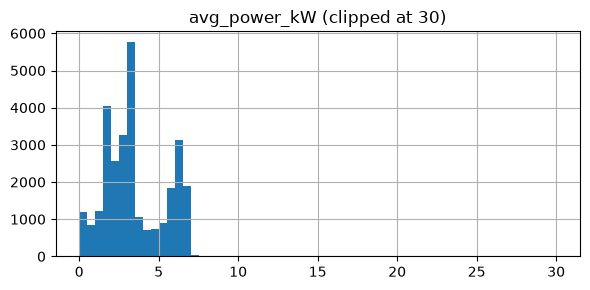

In [25]:
print(df["avg_power_kW"].describe(percentiles=[.5, .95, .99]).round(2))
for limit in (7, 10, 20):
    n = int((df["avg_power_kW"] > limit).sum())
    print(f"avg_power_kW > {limit} kW: {n} sessions ({n/len(df):.2%})")
df["avg_power_kW"].clip(upper=30).hist(bins=60, figsize=(6, 3))
plt.title("avg_power_kW (clipped at 30)"); plt.tight_layout(); plt.show()

Power above what the chargers can deliver is physically impossible and points to `doneChargingTime` landing seconds after connection. The sessions stay in the dataset; only the power value is nulled and flagged.

> **To verify:** `POWER_MAX_KW` (10 kW) is above the observed 99th percentile (≈6.8 kW), so sessions between 7 kW and the limit are kept and counted below. The limit should be confirmed against the rated power of the Caltech Level-2 chargers in the ACN-Data documentation, and lowered if the rating is lower.

In [26]:
# Capture the evidence BEFORE nulling, so the summary can report it
power_info = {
    "p99": float(df["avg_power_kW"].quantile(0.99)),
    "max": float(df["avg_power_kW"].max()),
    "n_gt7": int((df["avg_power_kW"] > 7).sum()),
    "n_7_to_limit": int(df["avg_power_kW"].between(7, POWER_MAX_KW, inclusive="right").sum()),
    "n_gt10": int((df["avg_power_kW"] > POWER_MAX_KW).sum()),
    "n_gt20": int((df["avg_power_kW"] > 20).sum()),
    "n_nonpositive_charging_h": int((df["charging_h"] <= 0).sum()),
    "n_no_doneTime": int(df["doneChargingTime"].isna().sum()),
}

df["power_implausible"] = df["avg_power_kW"] > POWER_MAX_KW
df.loc[df["power_implausible"], "avg_power_kW"] = np.nan
power_info["n_nulled"] = int(df["power_implausible"].sum())
power_info["n_power_null_total"] = int(df["avg_power_kW"].isna().sum())
power_info

{'p99': 6.845589767988299,
 'max': 1033.0122887864466,
 'n_gt7': 102,
 'n_7_to_limit': 63,
 'n_gt10': 39,
 'n_gt20': 17,
 'n_nonpositive_charging_h': 2,
 'n_no_doneTime': 2083,
 'n_nulled': 39,
 'n_power_null_total': 2124}

## 9. Final checks, validation and save

In [27]:
print("Final shape:", df.shape)
print("Rows kept: {:.2f}% of {}".format(len(df) / raw_rows * 100, raw_rows))
print("Date range (local):", df["date"].min(), "->", df["date"].max())
print("Stations:", df["stationID"].nunique())
print("Sessions with userID:", int(df["has_user_id"].sum()), f"({df['has_user_id'].mean():.1%})")
nulls = df.isna().sum()
print("\nRemaining nulls:\n", nulls[nulls > 0].to_string())

Final shape: (31387, 32)
Rows kept: 99.88% of 31424
Date range (local): 2018-04-25 -> 2021-09-13
Stations: 55
Sessions with userID: 16372 (52.2%)

Remaining nulls:
 userID                    15015
doneChargingTime           2083
doneChargingTime_local     2083
charging_h                 2083
avg_power_kW               2124
ui_milesRequested         15015
ui_WhPerMile              15015
ui_minutesAvailable       15015
ui_modifiedAt             15015
ui_paymentRequired        15015
ui_requestedDeparture     15015
ui_kWhRequested           15015
ui_departure_est          15015


In [28]:
# Validation: these must all hold for the dataset to be called analysis-ready
assert not df["_id"].duplicated().any()
assert not df["sessionID"].duplicated().any()
assert (df["disconnectTime"] > df["connectionTime"]).all()
assert df["kWhDelivered"].between(MIN_KWH, MAX_KWH).all()
assert (df["connected_h"] <= MAX_CONNECT_H).all()
assert (df["avg_power_kW"].dropna() <= POWER_MAX_KW).all()
assert len(df) + sum(len(f) for f in flagged) == raw_rows, "rows lost or duplicated"
# no gap longer than MAX_GAP_DAYS inside the final data, unless a large block was deliberately kept
final_days = pd.Series(sorted(pd.to_datetime(df["date"].unique())))
max_gap_final = int((final_days.diff().dt.days.max() or 1) - 1)
assert max_gap_final <= MAX_GAP_DAYS or len(large_other), f"gap of {max_gap_final} days left in the data"
print("All validation checks passed | longest empty run inside the data:", max_gap_final, "days")

All validation checks passed | longest empty run inside the data: 106 days


In [29]:
summary = pd.DataFrame(waterfall, columns=["step", "kind", "rows_remaining", "rows_affected"])

df.to_csv(ROOT / "acn_clean_sessions.csv", index=False)
summary.to_csv(ROOT / "preprocessing_summary.csv", index=False)
n_flagged = sum(len(f) for f in flagged)
if flagged:
    pd.concat(flagged).to_csv(ROOT / "acn_flagged_sessions.csv", index=False)

print("Saved acn_clean_sessions.csv:", df.shape)
print("Saved preprocessing_summary.csv")
print("Saved acn_flagged_sessions.csv:", n_flagged, "rows")
summary

Saved acn_clean_sessions.csv: (31387, 32)
Saved preprocessing_summary.csv
Saved acn_flagged_sessions.csv: 37 rows


,step,kind,rows_remaining,rows_affected
0,loaded,-,31424,0
1,outside contiguous coverage,ACTIVE,31424,0
2,duplicate _id,guard,31424,0
3,duplicate sessionID,guard,31424,0
4,duplicate station+connectionTime,guard,31424,0
5,unparseable connect/disconnect time,guard,31424,0
6,disconnect not after connect,guard,31424,0
7,doneChargingTime outside plug-in window -> NaT...,fix,31424,28
8,kWhDelivered missing/non-numeric,guard,31424,0
9,kWhDelivered < 0.1,guard,31424,0


## 10. Preprocessing summary (generated from the data above)

In [30]:
n_final = len(df)
active_removed = int(summary.loc[summary.kind == "ACTIVE", "rows_affected"].sum())
guard_removed = int(summary.loc[summary.kind == "guard", "rows_affected"].sum())
n_fragment = int(summary.loc[summary.step == "outside contiguous coverage", "rows_affected"].sum())
n_long = int(summary.loc[summary.step == f"connected > {MAX_CONNECT_H} h", "rows_affected"].sum())
n_done_missing = int(df["done_time_missing"].sum())
n_done_incons = int(df["done_time_inconsistent"].sum())
date_min, date_max = df["date"].min(), df["date"].max()
n_user = int(df["has_user_id"].sum())

check_rows = "\n".join(
    f"| {r.step} | {r.kind} | {r.rows_affected} |" for r in summary.itertuples() if r.step != "loaded"
)

# Observations recomputed on the cleaned data
spike = df[df["kWhDelivered"].between(13, 14)]
top_hours = ", ".join(f"{h}:00" for h in spike["hour"].value_counts().head(3).index)
st_clean, chi2_c, p_c, dof_c = spike_by_station(df)
short = df["connected_h"] < SHORT_STAY_H
FULL_API_TOTAL = 31424
partial = raw_rows < FULL_API_TOTAL
span_final = (pd.Timestamp(date_max) - pd.Timestamp(date_min)).days + 1

if partial:
    coverage_txt = (f"This is {raw_rows:,} of the {FULL_API_TOTAL:,} sessions the API reports. Collection stopped on repeated "
                    f"HTTP 502 / connection errors, and the collected pages are not contiguous: "
                    + ("; ".join(f"no sessions between {a} and {b} ({n} empty days)" for a, b, n in gap_list) if gap_list else "no gaps found")
                    + f". {n_fragment} sessions outside the main contiguous window were removed, so the analysis window is "
                    f"{date_min} to {date_max} ({span_final} days, ≈{span_final/30.4:.1f} months) and there is no full annual cycle.")
    limit1 = ("(1) Partial, non-contiguous collection; only the main contiguous window is used. Completing the collection "
              "by time window is tracked as a separate issue, and this notebook can be re-run unchanged on the larger file.")
else:
    gap_txt = ("; ".join(f"no sessions between {a} and {b} ({k} empty days)" for a, b, k in gap_list)) if gap_list else ""
    coverage_txt = (f"This is the complete set of {FULL_API_TOTAL:,} sessions reported by the API, covering "
                    f"{date_min} to {date_max} ({span_final} days)."
                    + (f" The source has a gap: {gap_txt}. Both sides are kept; downstream notebooks exclude the gap days." if gap_list else ""))
    limit1 = ("(1) " + (f"The {sum(k for _, _, k in gap_list)}-day recording gap must be excluded, not read as zero demand. " if gap_list else "")
              + (f"Very low-volume months ({', '.join(str(p) for p in low.index)}) are real but form a separate regime and should not be pooled with normal operation." if len(low) else "No unusually low-volume months."))

rule_txt = []
if n_fragment: rule_txt.append(f"an isolated block of {n_fragment} sessions outside the main time window (removed)")
rule_txt.append(f"impossible `doneChargingTime` values ({n_done_incons} sessions, value blanked, session kept)")
rule_txt.append(f"extreme connection times ({n_long} sessions removed, over {MAX_CONNECT_H:.0f} h; 99th percentile {p99_connect_h:.1f} h)")
interp_clean = ("Guard rules found nothing; the issues found were " if guard_removed == 0 else "Issues found were ") + ", ".join(rule_txt) + "."

dropped_txt = "; ".join(f"`{n}` ({w})" for n, w in dropped_cols) if dropped_cols else "none"
ui_txt = "; ".join(f"`{c}` {b} raw values, {a} parsed" for c, (b, a) in ui_parse.items())
spike_station_txt = (f"spike share by station ranges {st_clean['spike_share'].min():.1%}–{st_clean['spike_share'].max():.1%} "
                     f"(chi-square homogeneity test across stations with ≥50 sessions: p = {p_c:.3g}"
                     + ("; spike share differs between stations" if p_c < 0.05 else "; no evidence spike share differs between stations")
                     + ")")
overlap_txt = (f"{n_overlap} sessions start before the previous session on the same station ended (flagged `overlaps_prev_session`, kept)."
               if n_overlap else "No overlapping sessions on the same station.")

# userID share in the removed fragment (shows whether the share is stable over time)
frag = pd.concat(flagged) if flagged else pd.DataFrame(columns=["drop_reason", "userID"])
frag = frag[frag["drop_reason"] == "outside contiguous coverage"]
frag_uid = frag["userID"].notna().mean() if len(frag) else np.nan

limit2 = f"(2) User-level analysis is limited to the {n_user/n_final:.0%} of sessions with a `userID`"
if pd.notna(frag_uid):
    limit2 += (f"; the share is not stable over time ({frag_uid:.0%} in the removed fragment), "
               "so it should be re-checked on the full collection")
limit2 += "."

report = f"""## Issue #9: Preprocessing Summary

**Input.** {raw_rows:,} charging sessions, 13 fields, from the ACN-Data Caltech API. {coverage_txt}

**Result.** {n_final:,} sessions retained ({n_final/raw_rows:.2%}) in `acn_clean_sessions.csv` ({df.shape[1]} columns); {n_flagged} removed and listed with reasons in `acn_flagged_sessions.csv`. Rows removed by ACTIVE rules: {active_removed}; by guards: {guard_removed}.

| Step | Kind | Rows affected |
|---|---|---|
{check_rows}

**Interpretation.** {interp_clean} A further {n_done_missing} sessions never had a `doneChargingTime` (kept, flagged `done_time_missing`). {overlap_txt}

**Long sessions and occupancy.** The {n_long} sessions over {MAX_CONNECT_H:.0f} h are excluded from per-session energy and duration statistics only. They did occupy a charger, so occupancy and utilisation analysis should add them back from `acn_flagged_sessions.csv` (`drop_reason` = `connected > {MAX_CONNECT_H} h`).

**Transformations.** Timestamps converted UTC → America/Los_Angeles; `userInputs` flattened (latest entry; {n_multi_entry} sessions had more than one entry) into `ui_*` columns; user timestamps parsed with an explicit format ({ui_txt}); `ui_departure_est` = `ui_modifiedAt` + `ui_minutesAvailable`; flags `has_user_id`, `has_user_input`, `done_time_missing`, `done_time_inconsistent`, `power_implausible`, `overlaps_prev_session`; derived fields `connected_h`, `charging_h`, `avg_power_kW`, `hour`, `dayofweek`, `date`. Columns dropped: {dropped_txt}. User fields exist for {n_user:,} sessions ({n_user/n_final:.1%}).

**Average power check.** 99th percentile {power_info['p99']:.1f} kW; maximum before treatment {power_info['max']:,.0f} kW (likely `doneChargingTime` falling very shortly after connection; not individually verified). {power_info['n_gt7']} sessions exceeded 7 kW, of which {power_info['n_7_to_limit']} are between 7 kW and the {POWER_MAX_KW:.0f} kW limit and were kept; values above {POWER_MAX_KW:.0f} kW were nulled and flagged `power_implausible` ({power_info['n_nulled']} sessions, all kept). The limit should be confirmed against the chargers' rated power. {power_info['n_nonpositive_charging_h']} sessions had a non-positive charging duration. In total {power_info['n_power_null_total']} sessions have no usable `avg_power_kW`.

**Observations carried to analysis (recomputed on cleaned data).**
- {len(spike):,} sessions ({len(spike)/n_final:.1%}) deliver 13–14 kWh, a sharp spike. Most common arrival hours: {top_hours}. {spike['userID'].notna().mean():.1%} carry a `userID` (vs {df['has_user_id'].mean():.1%} overall); median stay {spike['connected_h'].median():.1f} h (vs {df['connected_h'].median():.1f} h overall). Normalised by each station's own session count, {spike_station_txt}. Cause not established.
- Connection time is bimodal: {short.mean():.1%} of sessions are under {SHORT_STAY_H:g} h (median {df.loc[short,'kWhDelivered'].median():.1f} kWh) and {(~short).mean():.1%} are {SHORT_STAY_H:g} h or longer (median {df.loc[~short,'kWhDelivered'].median():.1f} kWh). The split is set at the density valley between the two modes (≈{valley_h:.1f} h). A single demand model is likely to fit these groups poorly; segmentation should be considered.

**Limitations.** {limit1} {limit2} (3) `avg_power_kW` is unreliable wherever `doneChargingTime` is unreliable.
"""

with open(ROOT / "preprocessing_report.md", "w", encoding="utf-8") as f:
    f.write(report)
display(Markdown(report))

## Issue #9: Preprocessing Summary

**Input.** 31,424 charging sessions, 13 fields, from the ACN-Data Caltech API. This is the complete set of 31,424 sessions reported by the API, covering 2018-04-25 to 2021-09-13 (1238 days). The source has a gap: no sessions between 2020-08-03 and 2020-11-18 (106 empty days). Both sides are kept; downstream notebooks exclude the gap days.

**Result.** 31,387 sessions retained (99.88%) in `acn_clean_sessions.csv` (32 columns); 37 removed and listed with reasons in `acn_flagged_sessions.csv`. Rows removed by ACTIVE rules: 37; by guards: 0.

| Step | Kind | Rows affected |
|---|---|---|
| outside contiguous coverage | ACTIVE | 0 |
| duplicate _id | guard | 0 |
| duplicate sessionID | guard | 0 |
| duplicate station+connectionTime | guard | 0 |
| unparseable connect/disconnect time | guard | 0 |
| disconnect not after connect | guard | 0 |
| doneChargingTime outside plug-in window -> NaT (rows kept) | fix | 28 |
| kWhDelivered missing/non-numeric | guard | 0 |
| kWhDelivered < 0.1 | guard | 0 |
| kWhDelivered > 100.0 | guard | 0 |
| connected < 1.0 min | guard | 0 |
| connected > 72.0 h | ACTIVE | 37 |

**Interpretation.** Guard rules found nothing; the issues found were impossible `doneChargingTime` values (28 sessions, value blanked, session kept), extreme connection times (37 sessions removed, over 72 h; 99th percentile 21.7 h). A further 2055 sessions never had a `doneChargingTime` (kept, flagged `done_time_missing`). No overlapping sessions on the same station.

**Long sessions and occupancy.** The 37 sessions over 72 h are excluded from per-session energy and duration statistics only. They did occupy a charger, so occupancy and utilisation analysis should add them back from `acn_flagged_sessions.csv` (`drop_reason` = `connected > 72.0 h`).

**Transformations.** Timestamps converted UTC → America/Los_Angeles; `userInputs` flattened (latest entry; 2325 sessions had more than one entry) into `ui_*` columns; user timestamps parsed with an explicit format (`ui_requestedDeparture` 16372 raw values, 16372 parsed; `ui_modifiedAt` 16372 raw values, 16372 parsed); `ui_departure_est` = `ui_modifiedAt` + `ui_minutesAvailable`; flags `has_user_id`, `has_user_input`, `done_time_missing`, `done_time_inconsistent`, `power_implausible`, `overlaps_prev_session`; derived fields `connected_h`, `charging_h`, `avg_power_kW`, `hour`, `dayofweek`, `date`. Columns dropped: `ui_userID` (exact duplicate of userID); `siteID` (constant (2)); `clusterID` (constant (39)). User fields exist for 16,372 sessions (52.2%).

**Average power check.** 99th percentile 6.8 kW; maximum before treatment 1,033 kW (likely `doneChargingTime` falling very shortly after connection; not individually verified). 102 sessions exceeded 7 kW, of which 63 are between 7 kW and the 10 kW limit and were kept; values above 10 kW were nulled and flagged `power_implausible` (39 sessions, all kept). The limit should be confirmed against the chargers' rated power. 2 sessions had a non-positive charging duration. In total 2124 sessions have no usable `avg_power_kW`.

**Observations carried to analysis (recomputed on cleaned data).**
- 2,579 sessions (8.2%) deliver 13–14 kWh, a sharp spike. Most common arrival hours: 8:00, 9:00, 10:00. 24.4% carry a `userID` (vs 52.2% overall); median stay 6.6 h (vs 4.7 h overall). Normalised by each station's own session count, spike share by station ranges 3.5%–21.5% (chi-square homogeneity test across stations with ≥50 sessions: p = 2.62e-58; spike share differs between stations). Cause not established.
- Connection time is bimodal: 57.5% of sessions are under 6 h (median 5.9 kWh) and 42.5% are 6 h or longer (median 9.1 kWh). The split is set at the density valley between the two modes (≈5.9 h). A single demand model is likely to fit these groups poorly; segmentation should be considered.

**Limitations.** (1) The 106-day recording gap must be excluded, not read as zero demand. Very low-volume months (2020-04, 2020-05, 2020-06, 2020-07, 2020-08, 2020-11) are real but form a separate regime and should not be pooled with normal operation. (2) User-level analysis is limited to the 52% of sessions with a `userID`. (3) `avg_power_kW` is unreliable wherever `doneChargingTime` is unreliable.


In [31]:
# Evidence for the issue: files that must be committed
for fn in ["acn_clean_sessions.csv", "acn_flagged_sessions.csv", "preprocessing_summary.csv", "preprocessing_report.md"]:
    p = ROOT / fn
    print(f"{fn:45s}", f"{p.stat().st_size/1024:,.0f} KB" if p.exists() else "NOT FOUND")

acn_clean_sessions.csv                        12,435 KB
acn_flagged_sessions.csv                      14 KB
preprocessing_summary.csv                     1 KB
preprocessing_report.md                       4 KB


## Issue #9 checklist → where it is done

| Task | Section |
|---|---|
| Inspect missing values | 1, 6, 9 |
| Identify and handle duplicate records | 2, 6 |
| Validate timestamp fields and time coverage | 3, 6, 7 |
| Handle invalid or inconsistent values | 4, 6, 8 |
| Check numerical and categorical variables | 4, 4a, 5 |
| Apply appropriate preprocessing techniques | 7, 8 |
| Create the final analysis-ready dataset | 9 |

**Deliverables:** this notebook (with outputs saved), `acn_clean_sessions.csv`, `acn_flagged_sessions.csv`, `preprocessing_report.md` and `preprocessing_summary.csv`.